In [4]:
from google.colab import files
uploaded = files.upload()

Saving data_description.txt to data_description.txt
Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


In [5]:
import pandas as pd
import numpy as np
#Load datasets
train=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

#check dataset dimensions
print("Training data shape", train.shape)
print("Testing data shape", test.shape)

#display first 5 columns
display(train.head())

#display last 5 columns
display(train.tail())

#check columns name and data types
train.info()

#check missing values
print(train.isnull().sum().sort_values(ascending=False).head(20))

#Check target variables
print(train["SalePrice"].describe())

Training data shape (1460, 81)
Testing data shape (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

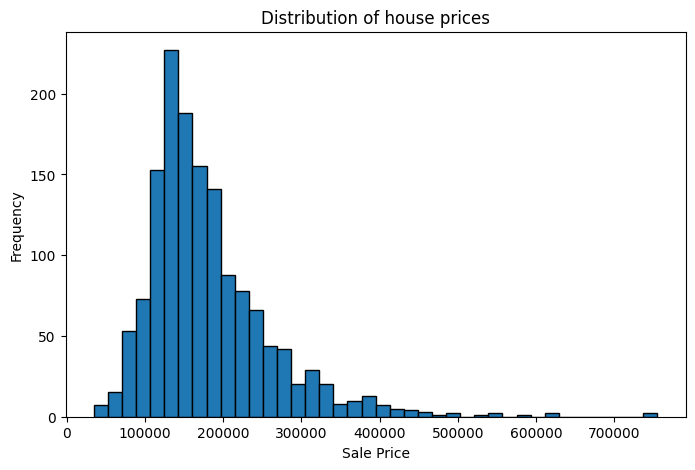

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(train["SalePrice"], bins=40, edgecolor="black")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.title("Distribution of house prices")
plt.show()

In [7]:
numeric_data = train.select_dtypes(include=np.number)
correlation = numeric_data.corr()["SalePrice"].sort_values(
    ascending=False
)
print(correlation.head(15))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


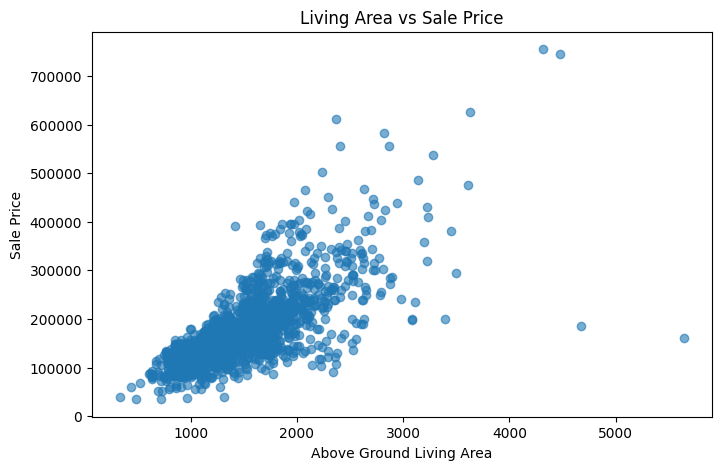

In [8]:
#Visualize the relationship between living area and price

plt.figure(figsize=(8, 5))
plt.scatter(train["GrLivArea"],
            train["SalePrice"],
            alpha=0.6
            )
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")
plt.title("Living Area vs Sale Price")
plt.show()

<Figure size 900x500 with 0 Axes>

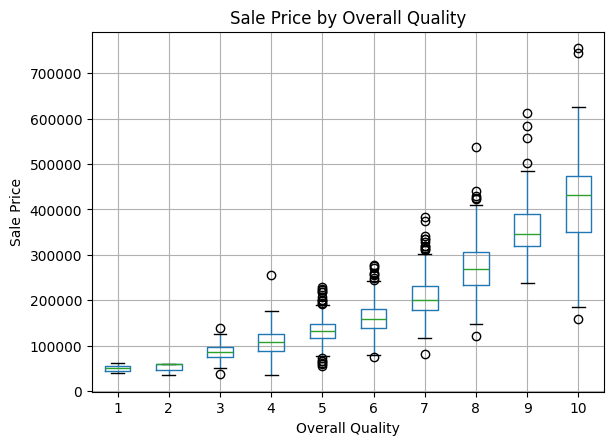

In [9]:
#Compare overall quality with house prices

plt.figure(figsize=(9, 5))
train.boxplot(
    column="SalePrice",
    by = "OverallQual"
)
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.title("Sale Price by Overall Quality")
plt.suptitle("")
plt.show()

In [29]:
import pandas as pd
import numpy as np

# Reload the datasets to ensure they are in memory
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Separate features and target variable
# Target variable
y = train["SalePrice"]

# Input features
X = train.drop(
    columns=["SalePrice", "Id"]
)

# Remove the identifier from test data
X_test = test.drop(
    columns=["Id"]
)

# Preserve test IDs for the final submission
test_ids = test["Id"]

print("Training features:", X.shape)
print("Target variable:", y.shape)
print("Test features:", X_test.shape)

Training features: (1460, 79)
Target variable: (1460,)
Test features: (1459, 79)


In [33]:
# Feature engineering
# Create copies to avoid modifying the original datasets
X = X.copy()
X_test = X_test.copy()

# Total usable area across major house sections
for df in [X, X_test]:
    df["TotalSF"] = (
        df["TotalBsmtSF"].fillna(0)
        + df["1stFlrSF"].fillna(0)
        + df["2ndFlrSF"].fillna(0)
    )

    # Total bathrooms, including half bathrooms
    df["TotalBathrooms"] = (
        df["FullBath"].fillna(0)
        + 0.5 * df["HalfBath"].fillna(0)
        + df["BsmtFullBath"].fillna(0)
        + 0.5 * df["BsmtHalfBath"].fillna(0)
    )

    # Total porch area
    df["TotalPorchSF"] = (
        df["OpenPorchSF"].fillna(0)
        + df["EnclosedPorch"].fillna(0)
        + df["3SsnPorch"].fillna(0)
        + df["ScreenPorch"].fillna(0)
        + df["WoodDeckSF"].fillna(0)
    )

print("Feature engineering completed!")
print("Updated training shape:", X.shape)
print("Updated test shape:", X_test.shape)

Feature engineering completed!
Updated training shape: (1460, 82)
Updated test shape: (1459, 82)


In [13]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical features
numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

Numerical features: 39
Categorical features: 43


In [15]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical features
numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

Numerical features: 39
Categorical features: 43


In [16]:
# Numerical preprocessing
numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    (
        "num",
        numeric_transformer,
        numerical_cols
    ),
    (
        "cat",
        categorical_transformer,
        categorical_cols
    )
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


**Linear Regression** **model**

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [43]:
# train the model
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [44]:
#predict house prices
linear_predictions = linear_model.predict(X_val)

print("First 10 predicted prices:")
print(linear_predictions[:10])

print("\nFirst 10 actual prices:")
print(y_val.iloc[:10].values)

First 10 predicted prices:
[154417.02913616 354127.06660321  93731.44422614 179515.74842942
 341967.42653748  62397.89853525 250348.8692371  151107.45005896
  57208.40010422 148247.84915808]

First 10 actual prices:
[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]


In [45]:
# evaluate the model
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_val, linear_predictions)

rmse = np.sqrt(
    mean_squared_error(y_val, linear_predictions)
)

r2 = r2_score(y_val, linear_predictions)

print("Linear Regression Evaluation")
print("----------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Linear Regression Evaluation
----------------------------
MAE:  20456.13
RMSE: 31261.53
R² Score: 0.8726


**Random Forest Model**

In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Create the Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [47]:
# Predict prices for the validation dataset
rf_predictions = rf_model.predict(X_val)

# Display the first 10 predictions
print("First 10 predicted prices:")
print(rf_predictions[:10])

print("\nFirst 10 actual prices:")
print(y_val.iloc[:10].values)

First 10 predicted prices:
[138871.75       345109.19666667 115013.33333333 156375.16666667
 315139.32333333  85519.66666667 202010.89       151983.97666667
  84704.77666667 132152.04      ]

First 10 actual prices:
[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]


In [48]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_val, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_predictions)
)

rf_r2 = r2_score(y_val, rf_predictions)

# Display results
print("Random Forest Evaluation")
print("-" * 35)
print(f"MAE:  ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"R² Score: {rf_r2:.4f}")

Random Forest Evaluation
-----------------------------------
MAE:  $17,369.59
RMSE: $29,288.38
R² Score: 0.8882


**Decision Tree regressor**

In [61]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# Hyperparameter combinations to test
configs = [
    {"max_depth": 4, "min_samples_split": 10, "min_samples_leaf": 5},
    {"max_depth": 5, "min_samples_split": 10, "min_samples_leaf": 5},
    {"max_depth": 6, "min_samples_split": 10, "min_samples_leaf": 5},
    {"max_depth": 6, "min_samples_split": 20, "min_samples_leaf": 5},
    {"max_depth": 6, "min_samples_split": 20, "min_samples_leaf": 10},
    {"max_depth": 7, "min_samples_split": 20, "min_samples_leaf": 5},
    {"max_depth": 8, "min_samples_split": 20, "min_samples_leaf": 5},
    {"max_depth": 8, "min_samples_split": 30, "min_samples_leaf": 10},
    {"max_depth": 10, "min_samples_split": 20, "min_samples_leaf": 10},
    {"max_depth": None, "min_samples_split": 20, "min_samples_leaf": 10}
]

results = []

for params in configs:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            **params,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )

    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    results.append({
        "max_depth": params["max_depth"],
        "min_samples_split": params["min_samples_split"],
        "min_samples_leaf": params["min_samples_leaf"],
        "Training_RMSE": train_rmse,
        "Validation_RMSE": val_rmse,
        "RMSE_Gap": val_rmse - train_rmse
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation_RMSE"
).reset_index(drop=True)

display(results_df.round(2))

print("\nBest configuration:")
print(results_df.iloc[0])

,max_depth,min_samples_split,min_samples_leaf,Training_RMSE,Validation_RMSE,RMSE_Gap
0,8.0,30,10,26552.32,36702.94,10150.62
1,NaN,20,10,24736.40,36929.36,12192.96
2,10.0,20,10,24745.35,36939.16,12193.81
3,6.0,20,10,27781.53,37082.51,9300.98
4,7.0,20,5,26258.96,37184.48,10925.52
5,6.0,20,5,27670.35,37194.89,9524.54
6,8.0,20,5,25087.96,37704.05,12616.08
7,5.0,10,5,28229.40,37839.91,9610.50
8,6.0,10,5,24918.16,38635.50,13717.34
9,4.0,10,5,32794.79,39168.49,6373.70



Best configuration:
max_depth                8.000000
min_samples_split       30.000000
min_samples_leaf        10.000000
Training_RMSE        26552.315625
Validation_RMSE      36702.936811
RMSE_Gap             10150.621186
Name: 0, dtype: float64


In [62]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

configs = [
    {"max_depth": 7, "min_samples_split": 30, "min_samples_leaf": 10},
    {"max_depth": 8, "min_samples_split": 40, "min_samples_leaf": 10},
    {"max_depth": 8, "min_samples_split": 30, "min_samples_leaf": 15},
    {"max_depth": 9, "min_samples_split": 30, "min_samples_leaf": 10},
    {"max_depth": 10, "min_samples_split": 30, "min_samples_leaf": 10},
    {"max_depth": 8, "min_samples_split": 50, "min_samples_leaf": 15},
    {"max_depth": 9, "min_samples_split": 40, "min_samples_leaf": 15},
    {"max_depth": None, "min_samples_split": 30, "min_samples_leaf": 15}
]

results = []

for params in configs:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            **params,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )

    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    log_rmse = np.sqrt(
        mean_squared_error(
            np.log1p(y_val),
            np.log1p(np.maximum(val_pred, 0))
        )
    )

    results.append({
        **params,
        "Training_RMSE": train_rmse,
        "Validation_RMSE": val_rmse,
        "Log_RMSE": log_rmse,
        "RMSE_Gap": val_rmse - train_rmse
    })

tuning_results = pd.DataFrame(results)

display(
    tuning_results.sort_values(
        "Validation_RMSE"
    ).reset_index(drop=True).round(4)
)

,max_depth,min_samples_split,min_samples_leaf,Training_RMSE,Validation_RMSE,Log_RMSE,RMSE_Gap
0,7.0,30,10,27201.2464,36498.7983,0.1841,9297.5518
1,8.0,40,10,27047.8478,36668.7936,0.1865,9620.9458
2,10.0,30,10,26179.7330,36684.5638,0.1862,10504.8308
3,9.0,30,10,26203.8059,36689.5792,0.1863,10485.7733
4,9.0,40,15,29561.0439,39429.7544,0.1831,9868.7105
5,8.0,50,15,30677.0577,39454.4621,0.1813,8777.4044
6,NaN,30,15,28832.1981,39847.6767,0.1830,11015.4786
7,8.0,30,15,28999.9854,39854.6776,0.1830,10854.6922


In [66]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

# Create the Decision Tree model
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
    max_depth=7,
    min_samples_split=30,
    min_samples_leaf=10,
    random_state=42
))
])

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree Regressor trained successfully!")

Decision Tree Regressor trained successfully!


In [67]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict validation prices
dt_predictions = dt_model.predict(X_val)

# Calculate evaluation metrics
dt_mae = mean_absolute_error(y_val, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_val, dt_predictions))
dt_r2 = r2_score(y_val, dt_predictions)

print("Decision Tree Evaluation")
print("-" * 35)
print(f"MAE:  ${dt_mae:,.2f}")
print(f"RMSE: ${dt_rmse:,.2f}")
print(f"R² Score: {dt_r2:.4f}")

Decision Tree Evaluation
-----------------------------------
MAE:  $22,918.70
RMSE: $36,498.80
R² Score: 0.8263


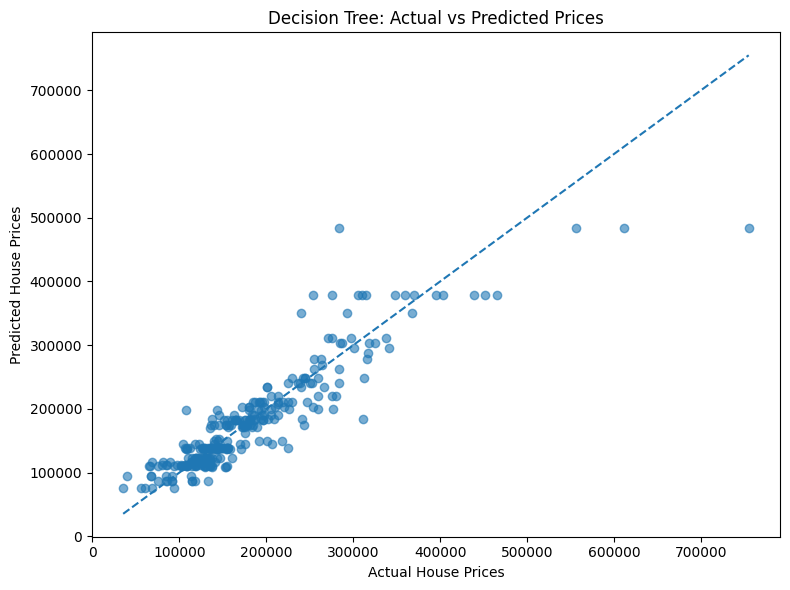

In [68]:
import matplotlib.pyplot as plt

# Predict prices on validation data
dt_predictions = dt_model.predict(X_val)

# Plot actual vs predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(y_val, dt_predictions, alpha=0.6)

# Reference line
min_price = min(y_val.min(), dt_predictions.min())
max_price = max(y_val.max(), dt_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Decision Tree: Actual vs Predicted Prices")

plt.tight_layout()
plt.show()

,Feature,Importance
3,num__OverallQual,0.574818
36,num__TotalSF,0.333116
25,num__GarageCars,0.029792
37,num__TotalBathrooms,0.014964
8,num__BsmtFinSF1,0.011720
192,cat__BsmtExposure_Gd,0.004690
51,cat__LotShape_Reg,0.004041
15,num__GrLivArea,0.002993
26,num__GarageArea,0.002580
23,num__Fireplaces,0.002523


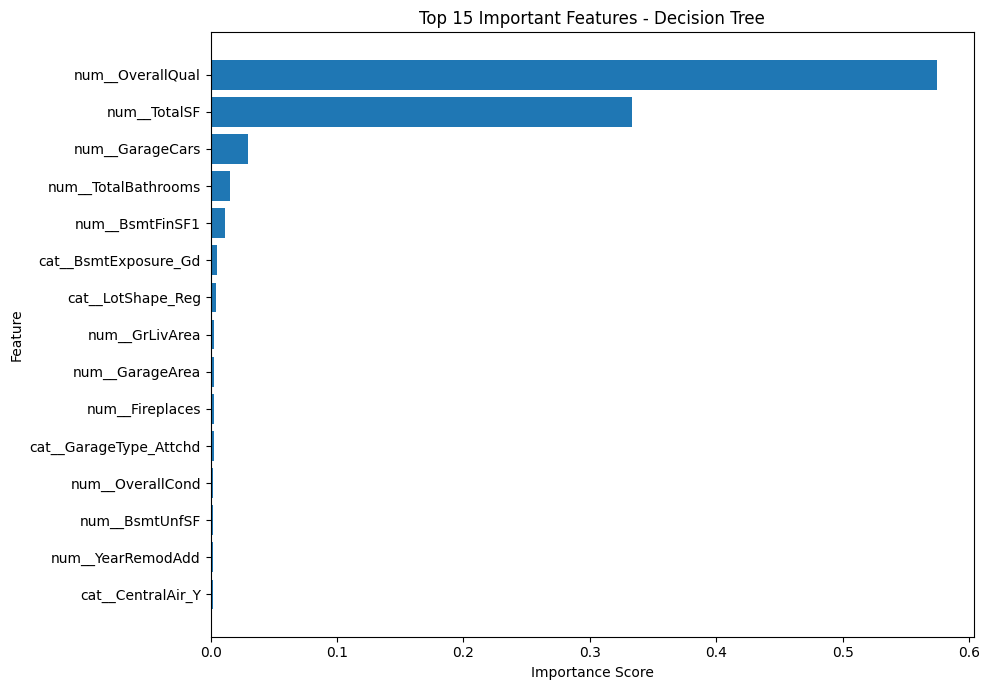

In [69]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract the trained Decision Tree
tree_model = dt_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    dt_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance scores
importance = tree_model.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort and display the top 15 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

# Plot top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 15 Important Features - Decision Tree")

plt.tight_layout()
plt.show()

In [70]:
#checking overfitting
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predictions on training data
dt_train_predictions = dt_model.predict(X_train)

# Predictions on validation data
dt_val_predictions = dt_model.predict(X_val)

# Calculate training metrics
dt_train_rmse = np.sqrt(
    mean_squared_error(y_train, dt_train_predictions)
)

dt_train_mae = mean_absolute_error(
    y_train, dt_train_predictions
)

dt_train_r2 = r2_score(
    y_train, dt_train_predictions
)

# Calculate validation metrics
dt_val_rmse = np.sqrt(
    mean_squared_error(y_val, dt_val_predictions)
)

dt_val_mae = mean_absolute_error(
    y_val, dt_val_predictions
)

dt_val_r2 = r2_score(
    y_val, dt_val_predictions
)

# Display results
dt_overfitting_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Training": [
        dt_train_mae,
        dt_train_rmse,
        dt_train_r2
    ],
    "Validation": [
        dt_val_mae,
        dt_val_rmse,
        dt_val_r2
    ]
})

display(dt_overfitting_results.round(4))

# Calculate the RMSE gap
dt_rmse_gap = dt_val_rmse - dt_train_rmse

print(f"\nRMSE Gap: ${dt_rmse_gap:,.2f}")

,Metric,Training,Validation
0,MAE,17706.3722,22918.6965
1,RMSE,27201.2464,36498.7983
2,R2 Score,0.8759,0.8263



RMSE Gap: $9,297.55


Gradient Boosting regressor

In [36]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gb_model.fit(X, y)

print("Gradient Boosting model trained successfully!")

# Make predictions
gb_predictions = gb_model.predict(X)

# Evaluate the model
gb_results = evaluate_model(
    y,
    gb_predictions,
    "Gradient Boosting Regressor"
)

Gradient Boosting model trained successfully!

Gradient Boosting Regressor
------------------------------
MAE:  10098.33
RMSE: 13752.36
R²:   0.9700


EXtra Tree regressor

In [37]:
from sklearn.ensemble import ExtraTreesRegressor

et_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
et_model.fit(X, y)

print("Extra Trees model trained successfully!")

# Make predictions
et_predictions = et_model.predict(X)

# Evaluate the model
et_results = evaluate_model(
    y,
    et_predictions,
    "Extra Trees Regressor"
)

Extra Trees model trained successfully!

Extra Trees Regressor
------------------------------
MAE:  0.00
RMSE: 0.00
R²:   1.0000


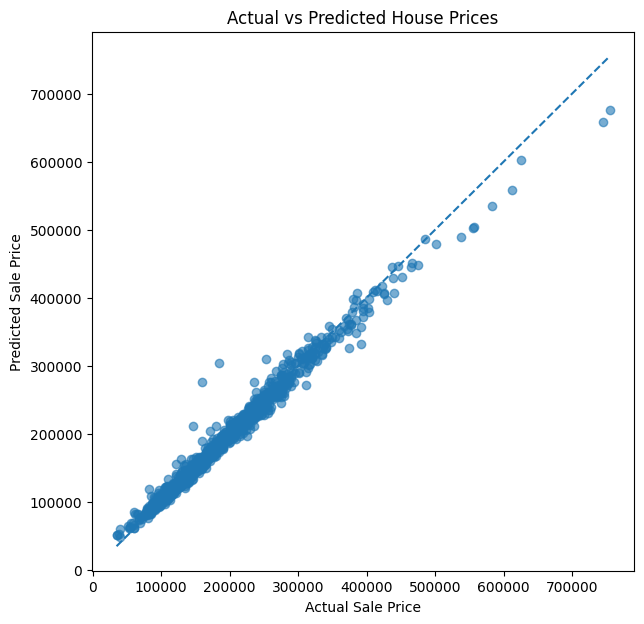

In [41]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y,
    rf_predictions,
    alpha=0.6
)

min_price = min(y.min(), rf_predictions.min())
max_price = max(y.max(), rf_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [79]:
#identify which model have inconsistent features
for name, model in models.items():
    print(f"\n{name}")

    print("Current X_train shape:", X_train.shape)

    try:
        print("Expected input features:", model.n_features_in_)
    except AttributeError:
        try:
            print(
                "Expected input features:",
                model.named_steps["preprocessor"].n_features_in_
            )
        except (AttributeError, KeyError):
            print("Check the model's preprocessing pipeline.")


Linear Regression
Current X_train shape: (1168, 82)
Expected input features: 82

Random Forest
Current X_train shape: (1168, 82)
Expected input features: 82

Decision Tree
Current X_train shape: (1168, 82)
Expected input features: 82

Gradient Boosting
Current X_train shape: (1168, 82)
Expected input features: 82

Extra Trees
Current X_train shape: (1168, 82)
Expected input features: 82


In [80]:
#check the transformed feature count
for name, model in models.items():
    print(f"\n{name}")

    transformed_train = model.named_steps["preprocessor"].transform(X_train)

    print("Original features:", X_train.shape[1])
    print("Transformed features:", transformed_train.shape[1])
    print(
        "Model expects:",
        model.named_steps["model"].n_features_in_
    )


Linear Regression
Original features: 82
Transformed features: 288
Model expects: 288

Random Forest
Original features: 82
Transformed features: 288
Model expects: 288

Decision Tree
Original features: 82
Transformed features: 288
Model expects: 288

Gradient Boosting
Original features: 82
Transformed features: 288
Model expects: 290

Extra Trees
Original features: 82
Transformed features: 288
Model expects: 290


In [81]:
# Retrain Gradient Boosting
gb_model.fit(X_train, y_train)

# Retrain Extra Trees
et_model.fit(X_train, y_train)

print("Gradient Boosting and Extra Trees retrained successfully!")

Gradient Boosting and Extra Trees retrained successfully!


In [82]:
#verify the mismatch is fixed
for name, model in models.items():
    transformed_features = (
        model.named_steps["preprocessor"]
        .transform(X_train)
        .shape[1]
    )

    expected_features = model.named_steps["model"].n_features_in_

    print(
        f"{name}: Transformed = {transformed_features}, "
        f"Expected = {expected_features}"
    )

Linear Regression: Transformed = 288, Expected = 288
Random Forest: Transformed = 288, Expected = 288
Decision Tree: Transformed = 288, Expected = 288
Gradient Boosting: Transformed = 288, Expected = 288
Extra Trees: Transformed = 288, Expected = 288


In [85]:
#compare all the models
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []

for name, model in models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    results.append({
        "Model": name,
        "Training RMSE": train_rmse,
        "Validation RMSE": val_rmse,
        "RMSE Gap": val_rmse - train_rmse,
        "Training R2": r2_score(y_train, train_pred),
        "Validation R2": r2_score(y_val, val_pred)
    })

results_df = pd.DataFrame(results).sort_values(
    by="Validation RMSE"
).reset_index(drop=True)

display(results_df.round(4))

,Model,Training RMSE,Validation RMSE,RMSE Gap,Training R2,Validation R2
0,Gradient Boosting,12949.3904,26899.5045,13950.1141,0.9719,0.9057
1,Extra Trees,0.0000,27394.8687,27394.8687,1.0000,0.9022
2,Random Forest,10904.9522,29288.3793,18383.4271,0.9801,0.8882
3,Linear Regression,24353.0684,31261.5294,6908.4610,0.9006,0.8726
4,Decision Tree,27201.2464,36498.7983,9297.5518,0.8759,0.8263


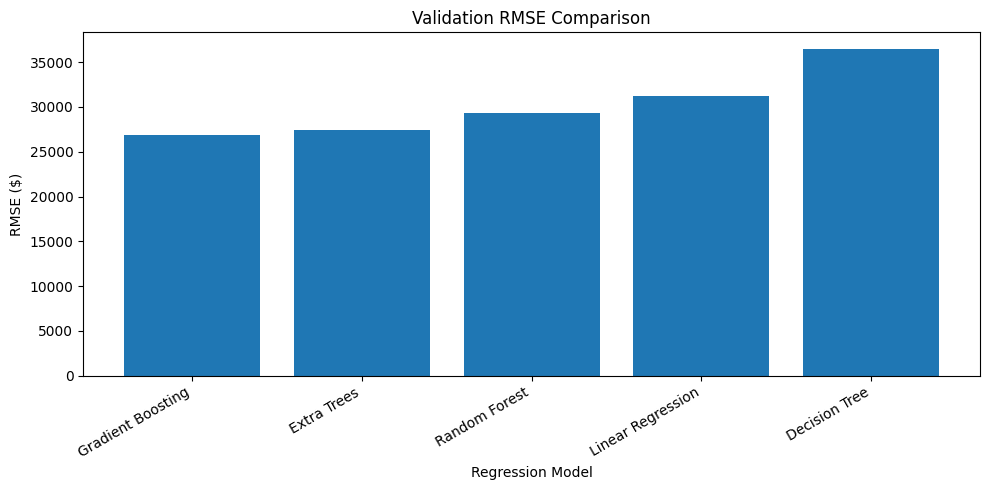

In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Validation RMSE"]
)

plt.title("Validation RMSE Comparison")
plt.xlabel("Regression Model")
plt.ylabel("RMSE ($)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [87]:
#Reduce Gradient Boosting overfitting

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

configs = [
    {"n_estimators": 100, "learning_rate": 0.05,
     "max_depth": 2, "min_samples_leaf": 5},

    {"n_estimators": 200, "learning_rate": 0.05,
     "max_depth": 2, "min_samples_leaf": 5},

    {"n_estimators": 200, "learning_rate": 0.03,
     "max_depth": 2, "min_samples_leaf": 10},

    {"n_estimators": 300, "learning_rate": 0.03,
     "max_depth": 2, "min_samples_leaf": 10},

    {"n_estimators": 200, "learning_rate": 0.05,
     "max_depth": 3, "min_samples_leaf": 10},

    {"n_estimators": 100, "learning_rate": 0.05,
     "max_depth": 3, "min_samples_leaf": 10}
]

tuning_results = []

for config in configs:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            **config,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )

    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_pred)
    )

    tuning_results.append({
        **config,
        "Training RMSE": train_rmse,
        "Validation RMSE": val_rmse,
        "RMSE Gap": val_rmse - train_rmse,
        "Validation R2": r2_score(y_val, val_pred)
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="Validation RMSE"
).reset_index(drop=True)

display(tuning_df.round(4))

,n_estimators,learning_rate,max_depth,min_samples_leaf,Training RMSE,Validation RMSE,RMSE Gap,Validation R2
0,200,0.05,2,5,19285.7818,28470.9658,9185.1840,0.8943
1,200,0.05,3,10,15285.0749,28571.5769,13286.5019,0.8936
2,100,0.05,3,10,19630.4818,29572.1015,9941.6197,0.8860
3,300,0.03,2,10,21410.4728,31122.0305,9711.5577,0.8737
4,100,0.05,2,5,24623.8238,31472.7952,6848.9713,0.8709
5,200,0.03,2,10,24201.2788,32208.2013,8006.9225,0.8648


In [88]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

print("Best current Gradient Boosting model trained!")

Best current Gradient Boosting model trained!


In [89]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
import numpy as np
import pandas as pd

# Five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model configurations to compare
configurations = {
    "Gradient Boosting (Depth 2)": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    ),
    "Gradient Boosting (Depth 3)": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

cv_results = []

for name, estimator in configurations.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    scores = cross_val_score(
        model,
        X_train,
        np.log1p(y_train),
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    rmse_scores = -scores

    cv_results.append({
        "Model": name,
        "Mean CV Log-RMSE": rmse_scores.mean(),
        "Std CV Log-RMSE": rmse_scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    by="Mean CV Log-RMSE"
)

display(cv_df.round(5))

,Model,Mean CV Log-RMSE,Std CV Log-RMSE
1,Gradient Boosting (Depth 3),0.12659,0.01512
0,Gradient Boosting (Depth 2),0.13088,0.01666


In [94]:
import numpy as np
from sklearn.metrics import mean_squared_error

val_predictions = gb_model.predict(X_val)

validation_log_rmse = np.sqrt(
    mean_squared_error(
        np.log1p(y_val),
        np.log1p(np.maximum(val_predictions, 0))
    )
)

print(f"Validation Log-RMSE: {validation_log_rmse:.5f}")

Validation Log-RMSE: 0.13713


In [96]:
print("TotalSF in X_train:", "TotalSF" in X_train.columns)
print("TotalSF in X_val:", "TotalSF" in X_val.columns)
print("TotalSF in test:", "TotalSF" in X_test.columns)

print("Training columns:", X_train.shape[1])

TotalSF in X_train: True
TotalSF in X_val: True
TotalSF in test: True
Training columns: 82


In [97]:
# Create TotalSF in training, validation, and test datasets

for df in [X_train, X_val, X_test]:
    df["TotalSF"] = (
        df["1stFlrSF"]
        + df["2ndFlrSF"]
        + df["TotalBsmtSF"].fillna(0)
    )

print("TotalSF created successfully!")
print(X_train[["1stFlrSF", "2ndFlrSF", "TotalBsmtSF", "TotalSF"]].head())

TotalSF created successfully!
      1stFlrSF  2ndFlrSF  TotalBsmtSF  TotalSF
254       1314         0         1314     2628
1066       799       772          799     2370
638        796         0          796     1592
799        981       787          731     2499
380       1026       665         1026     2717


In [98]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np

# Identify numerical and categorical columns again
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Preprocessing pipeline recreated successfully!")
print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))
print("Total input features:", len(numerical_cols) + len(categorical_cols))

Preprocessing pipeline recreated successfully!
Numerical features: 39
Categorical features: 43
Total input features: 82


In [99]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Create the model
gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Train
gb_model.fit(X_train, y_train)

# Predict on validation data
val_predictions = gb_model.predict(X_val)

# Evaluate
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
r2 = r2_score(y_val, val_predictions)

log_rmse = np.sqrt(
    mean_squared_error(
        np.log1p(y_val),
        np.log1p(np.maximum(val_predictions, 0))
    )
)

print(f"Validation RMSE: ${rmse:,.2f}")
print(f"Validation R²: {r2:.4f}")
print(f"Validation Log-RMSE: {log_rmse:.5f}")

Validation RMSE: $26,899.50
Validation R²: 0.9057
Validation Log-RMSE: 0.13713


In [100]:
#most imp features
import pandas as pd

# Extract the trained Gradient Boosting estimator
gb_estimator = gb_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    gb_model.named_steps["preprocessor"].get_feature_names_out()
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_estimator.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display the top 15 features
display(importance_df.head(15).round(5))

,Feature,Importance
0,num__TotalSF,0.41461
1,num__OverallQual,0.30858
2,num__TotalBathrooms,0.02697
3,num__YearBuilt,0.02641
4,num__2ndFlrSF,0.02578
5,num__GarageCars,0.02132
6,cat__BsmtQual_Ex,0.01716
7,num__BsmtFinSF1,0.01637
8,num__GrLivArea,0.01608
9,cat__GarageFinish_Unf,0.01550


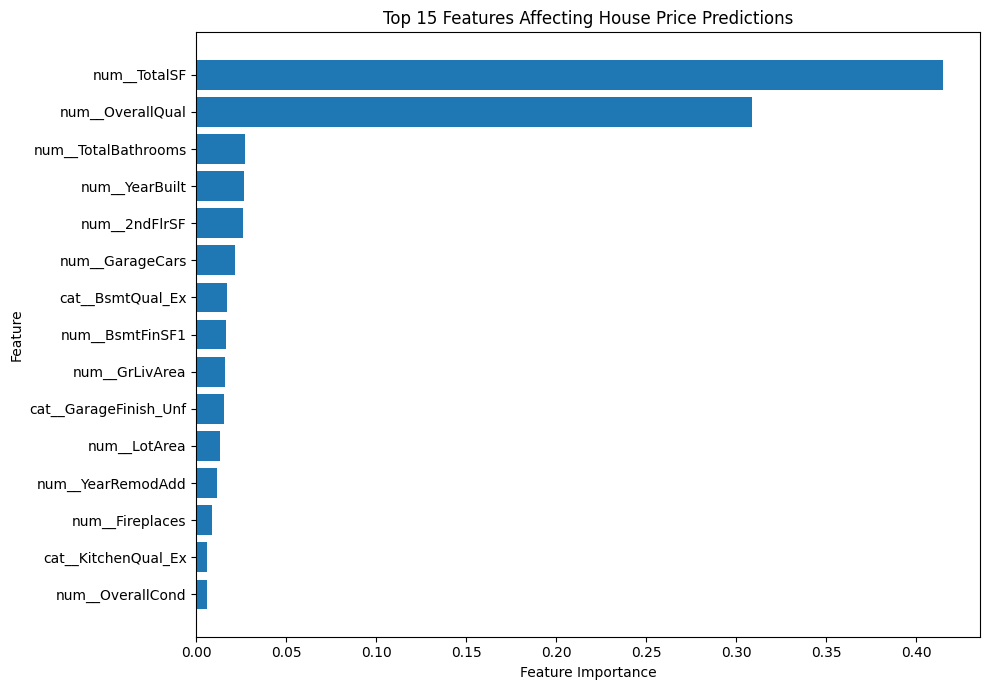

In [101]:
#visualise the top 15 features
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Affecting House Price Predictions")
plt.tight_layout()
plt.show()

Validation MAE: $16,159.44
Validation RMSE: $26,899.50
Validation R2 Score: 0.9057


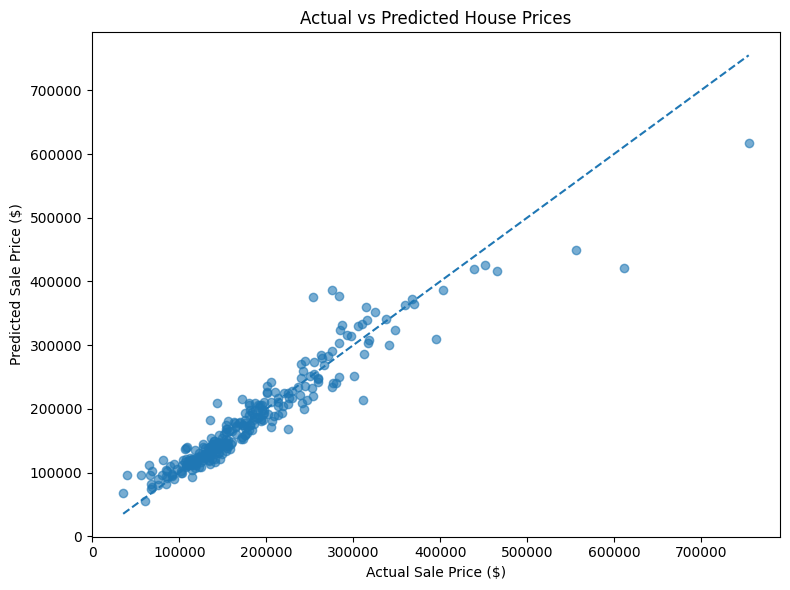

In [104]:
#actual vs predicted prices
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generate validation predictions
val_predictions = gb_model.predict(X_val)

# Calculate metrics
mae = mean_absolute_error(y_val, val_predictions)

rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

r2 = r2_score(y_val, val_predictions)

print(f"Validation MAE: ${mae:,.2f}")
print(f"Validation RMSE: ${rmse:,.2f}")
print(f"Validation R2 Score: {r2:.4f}")

# Plot actual vs predicted
plt.figure(figsize=(8, 6))

plt.scatter(y_val, val_predictions, alpha=0.6)

minimum = min(y_val.min(), val_predictions.min())
maximum = max(y_val.max(), val_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Actual vs Predicted House Prices")

plt.tight_layout()
plt.show()

In [105]:
# Prepare the full training dataset
X_full = train.drop(
    columns=["SalePrice", "Id"]
).copy()

y_full = train["SalePrice"].copy()

# Prepare the Kaggle test dataset
X_test_final = test.drop(
    columns=["Id"]
).copy()

# Create the engineered feature consistently
for df in [X_full, X_test_final]:
    df["TotalSF"] = (
        df["1stFlrSF"]
        + df["2ndFlrSF"]
        + df["TotalBsmtSF"].fillna(0)
    )

print("Full training shape:", X_full.shape)
print("Test shape:", X_test_final.shape)

Full training shape: (1460, 80)
Test shape: (1459, 80)


In [106]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
import numpy as np

numerical_cols = X_full.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_full.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

preprocessor_final = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

final_model = Pipeline([
    ("preprocessor", preprocessor_final),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

final_model.fit(X_full, y_full)

print("Final model trained successfully!")

Final model trained successfully!


In [107]:
test_predictions = final_model.predict(X_test_final)

# House prices should not be negative
test_predictions = np.maximum(test_predictions, 0)

print("Number of predictions:", len(test_predictions))
print("First 10 predictions:")
print(test_predictions[:10])

Number of predictions: 1459
First 10 predictions:
[122845.81608881 165201.26865965 185547.47206219 189710.05237055
 184228.54272303 173734.17072796 174208.77436418 167562.1093046
 190003.10068441 126384.06252403]


In [108]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print("Submission file created successfully!")

     Id      SalePrice
0  1461  122845.816089
1  1462  165201.268660
2  1463  185547.472062
3  1464  189710.052371
4  1465  184228.542723
Submission file created successfully!


In [109]:
from google.colab import files

files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>